**Instructions:**

- Do not write your name on the assignment. Be careful about any warnings that might display some file path with your name included.
- Receiving help from classmates and/or ideas from Generative AI is allowed. **However, you must submit your own original work.**
- For questions that require coding, you need to write the relevant code and display its output. Your output should either be the direct answer to the question or clearly display the answer in it.
- For questions that require a written answer (sometimes along with the code), you need to put your answer in a Markdown cell. Writing the answer as a comment or as a print line is not acceptable.
- You need to render this file as HTML using Quarto and submit the HTML file. **Please note that this is a requirement and not optional.** A submission cannot be graded until it is properly rendered.

Import all the libraries and tools you need below.

In [3]:
# You need the line given below to install the UMAP library.
#!pip install umap-learn

import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import umap

**Before you start, please note that the interpretations of some figures you will create can be open-ended, since there is not any numeric evaluation in this assignment. Answer the questions that concern the output figures according to what you see on the figures.**

### 1)

Read the data from **customer_churn.csv**. Each observation represents a customer in a telecommunications company. The `Churn` variable represents whether the customer cancelled (1) their subscription at the end of a 12-month period or not (0) and is the target/response variable. All the other variables are the features. Their names should be self-explanatory.

Separate the response and the features. You will not predict anything in this assignment, so the responses will be for color-coding the classes only.

**(2.5 points)**

In [4]:
df = pd.read_csv("customer_churn.csv")

X = df.drop(columns=["Churn"])
y = df["Churn"]

### 2) 

(Standard) scale the features. Note that you will use the entire dataset in this part and the remainder of this assignment. **(2.5 points)**

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### 3)

Using Principal Component Analysis (PCA), reduce the data to two dimensions. Find and print the percentage of variance from the original data that is retained by the lower-dimensional data. **(10 points)**

In [6]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

retained_variance = pca.explained_variance_ratio_.sum() * 100

print("Retained variance:", retained_variance, "%")

Retained variance: 48.74623541704387 %


### 4)

Create a scatter plot of the lower-dimensional data and color-code the points with the classes. Set the transparency of the points to 0.1, so you can see the overlapping classes well. 

Do the classes look separable by any classifier that is trained on the lower-dimensional data? How does this relate to the retained variance you found in the previous question? 

**(10 points)**

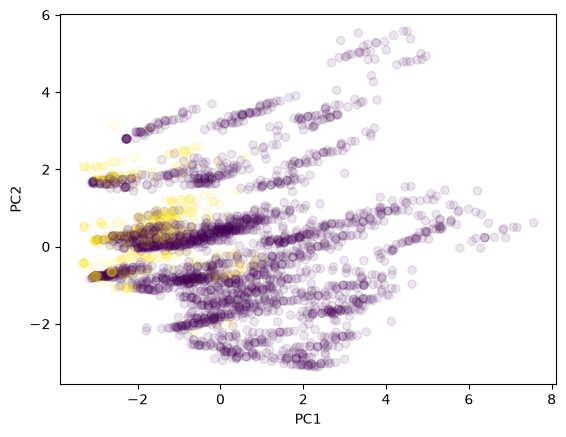

In [7]:
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, alpha=0.1)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

The classes are not clearly separable because there is a lot of overlap between them but customers who churned are more concentrated on the left side of the graph. PCA only retained 48.75% of the original variance, meaning more than half was lost. This could explain why separating the classes using only these two dimensions is difficult. PCA focuses on preserving variance rather than separating classes.

### 5)

One way to possibly improve the retained information during dimensionality reduction is to use a [Kernelized PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.KernelPCA.html) model. Explain why kernelization can be more beneficial while applying PCA to a dataset. **(5 points)**

Kernel PCA can be better than regular PCA because it can capture nonlinear relationships between features. Regular PCA only looks for linear patterns, so it misses some important information. Using a kernel can help preserve more useful patterns when reducing the data to fewer dimensions.

### 6)

Either using a loop or manually, repeat Questions 3 and 4 with: (1) an `rbf` kernel with a gamma value of 0.1, 1 and 10 and (2) a `poly` kernel with a degree of 2, 3, and 4. Does the lower-dimensional representation get more classifiable?

**Note:** You need to display 6 figures in total.

**(15 points)**

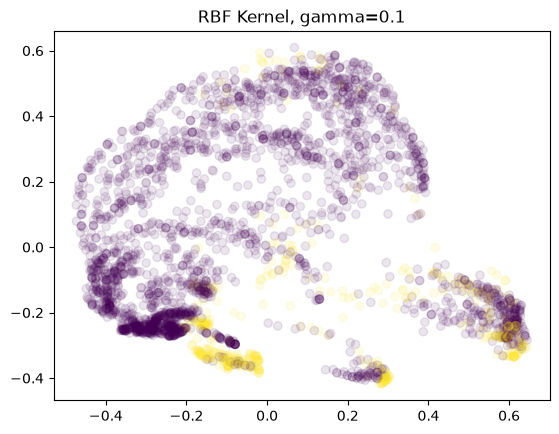

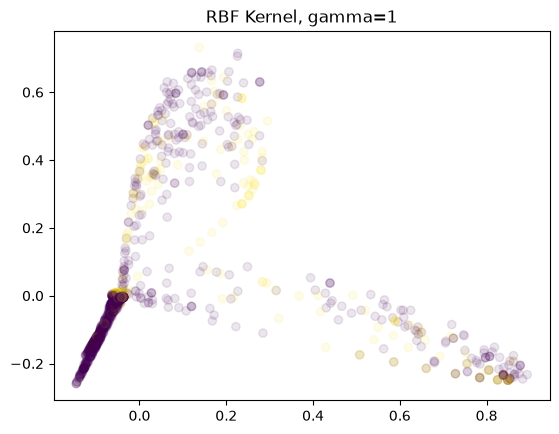

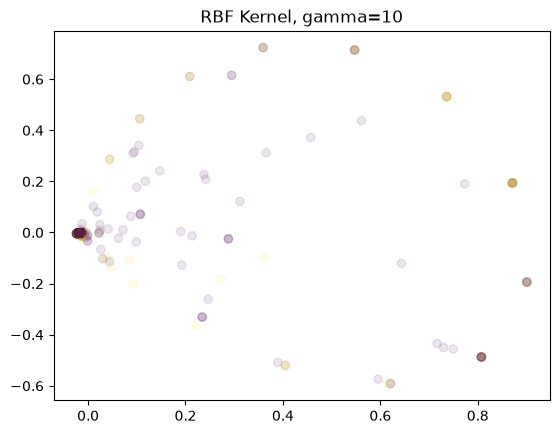

In [8]:
for gamma in [0.1, 1, 10]:
    kpca = KernelPCA(n_components=2, kernel="rbf", gamma=gamma)
    X_kpca = kpca.fit_transform(X_scaled)

    plt.scatter(X_kpca[:, 0], X_kpca[:, 1], c=y, alpha=0.1)
    plt.title(f"RBF Kernel, gamma={gamma}")
    plt.show()

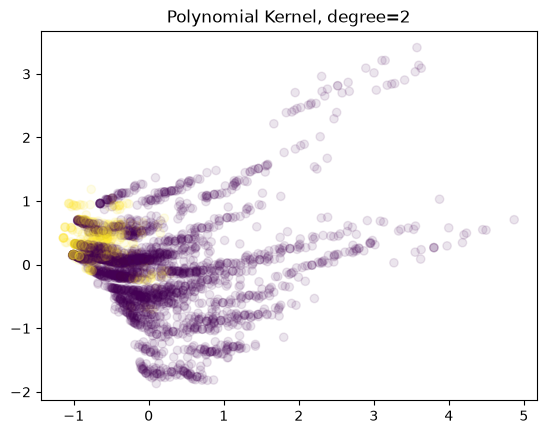

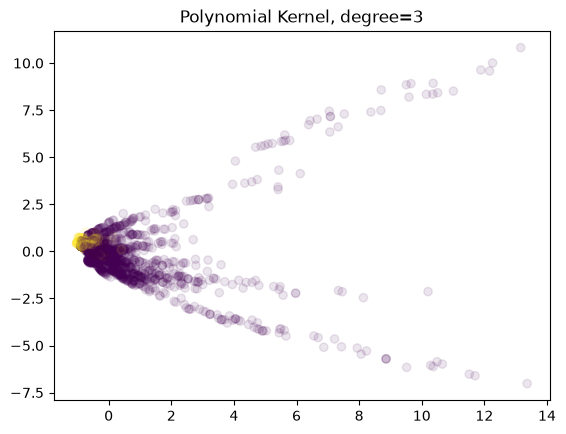

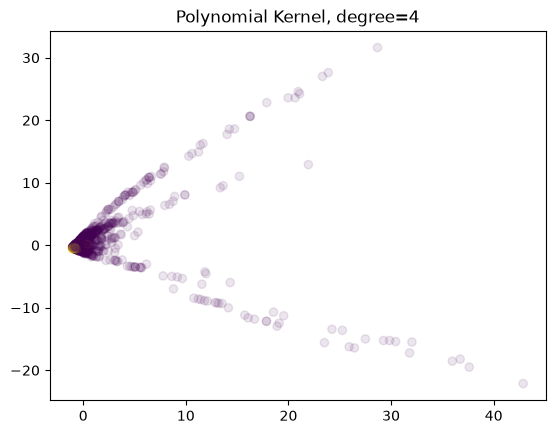

In [9]:
for degree in [2, 3, 4]:
    kpca = KernelPCA(n_components=2, kernel="poly", degree=degree)
    X_kpca = kpca.fit_transform(X_scaled)

    plt.scatter(X_kpca[:, 0], X_kpca[:, 1], c=y, alpha=0.1)
    plt.title(f"Polynomial Kernel, degree={degree}")
    plt.show()

Kernel PCA does not seem to improve class separation significantly compared to regular PCA. The RBF kernel with gamma = 0.1 and 1 shows some separation in certain regions, but there is still a lot of overlap. With gamma = 10, the representation becomes more scattered. The polynomial kernels also show considerable overlap, particularly near the origin. Overall, changing the kernel and its parameters changes the shape of the data, but does not make the classes clearly separable.

### 7)

Reduce the data to two dimensions using a [T-SNE]() model. Use `random_state=2` and **the 40 nearest neighbors** of an observation to find its place in two dimensions. Recreate the color-coded scatter plot of the lower-dimensional data. Use a transparency of 0.1 again. Do the classes look more separable with T-SNE (compared to PCA)?

**(15 points)**

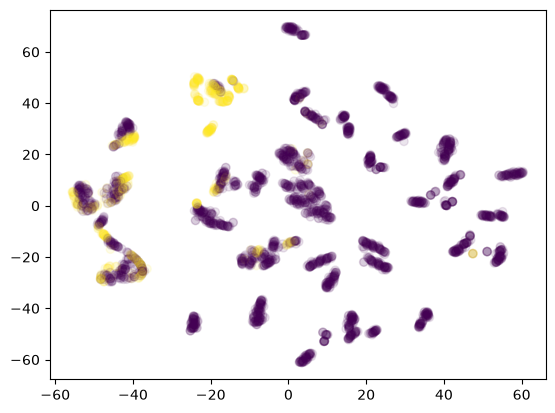

In [10]:
tsne = TSNE(n_components=2, perplexity=40, random_state=2)
X_tsne = tsne.fit_transform(X_scaled)

plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, alpha=0.1)
plt.show()

T-SNE separates the classes better than PCA. The points form clearer groups, and customers who churned are mostly on the left. However, there is still some overlap between the two classes.

### 8)

In the previous questions, you should have observed that dimensionality reduction with T-SNE takes much longer to run than PCA. Why is this the case? How would the runtime change as the number of neighbors in T-SNE increase? **(10 points)**

T-SNE takes longer than PCA because it uses many steps to find the best positions for the points, while PCA uses simpler calculations. As the number of neighbors increases, T-SNE generally takes longer because it has to consider more relationships between points.

### 9)

Reduce the data to two dimensions using a [UMAP](https://umap-learn.readthedocs.io/en/latest/index.html) model. Use `random_state=2`. Read about the model behavior with `n_neighbors` and `min_dist` inputs in the (linked) model documentation. You will only use these two inputs in this question and leave the other inputs (except `random_state`) as default.

Set `n_neighbors` and `min_dist` to values that return the most classifiable two-dimensional representation of the data in this assignment (maybe except Kernelized PCA).  Recreate the color-coded scatter plot of the lower-dimensional data. Use a transparency of 0.1 again.

**Note:** Tuning the two main inputs of UMAP entirely consists of trial and error. Just try out different values and observe how the two-dimensional representation looks.

**(20 points)**

### 10)

For the T-SNE and UMAP models, do the new dimensions have any insight? Can they be formulated like the Principal Components of PCA? How about captured variance for each dimension? What does this say about the T-SNE and UMAP models? **(10 points)**